# ML for SWRO performance prediction — Industrial water for a power plant
**Course:** 2107541 ML for Environmental Applications

**Environmental problem:** We build ML surrogates that predict *permeate flow*, *permeate salinity* and *specific energy consumption (SEC)* from operating conditions, then use SHAP to see what controls them.

**Dataset:** simulated 18,816 scenarios (7 feed flows × 16 temperatures × 8 salinities × 21 pressures) from a solution-diffusion model (`swro_sim.py`) following the grid of Daaboub et al. (2024, FAIA 386). *Not real plant data.*

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings, time
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
import shap
plt.rcParams.update({'figure.dpi':110,'font.size':9})
df = pd.read_csv('../data/swro_simulated.csv'); print(df.shape); df.describe().T

(18816, 7)


,count,mean,std,min,25%,50%,75%,max
feed_flow_m3h,18816.0,11.000000,4.000106,5.000000,7.000000,11.000000,15.000000,17.000000
feed_temp_C,18816.0,25.000000,9.219789,10.000000,17.500000,25.000000,32.500000,40.000000
feed_salinity_gL,18816.0,37.000000,4.582697,30.000000,33.500000,37.000000,40.500000,44.000000
feed_pressure_bar,18816.0,60.000000,12.110923,40.000000,50.000000,60.000000,70.000000,80.000000
permeate_flow_m3h,18816.0,3.527865,1.474877,0.556870,2.408538,3.366141,4.544380,8.722345
permeate_salinity_gL,18816.0,0.254933,0.145210,0.063558,0.157466,0.217529,0.309087,1.732655
SEC_kWh_m3,18816.0,6.992314,3.024080,3.387869,4.941041,6.256106,8.072625,30.424122


## 1–2. Define the problem & data check

0 missing values


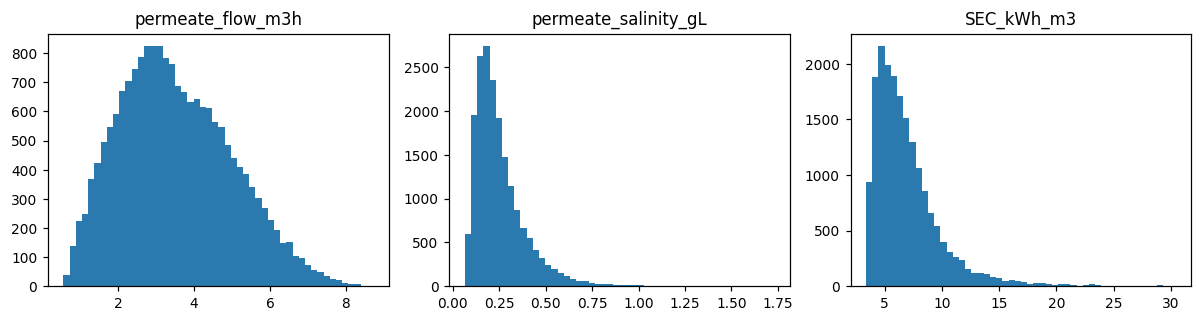

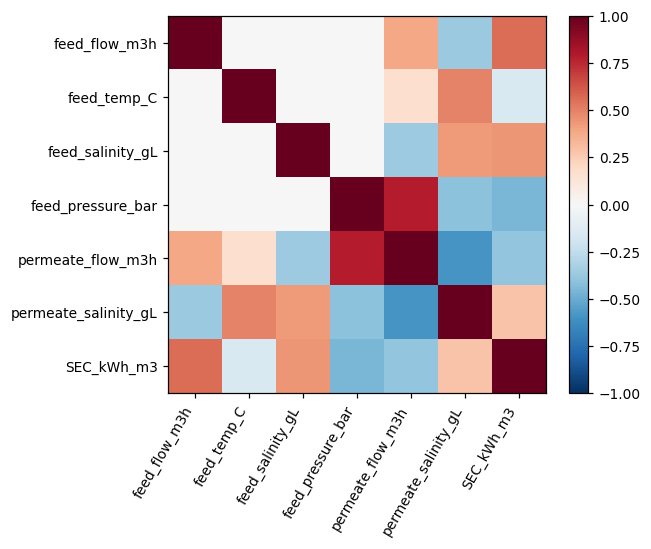

In [ ]:
print(df.isna().sum().sum(), 'missing values')
fig,ax=plt.subplots(1,3,figsize=(11,3))
for a,c in zip(ax,['permeate_flow_m3h','permeate_salinity_gL','SEC_kWh_m3']):
    a.hist(df[c],bins=50,color='#2a7ab0'); a.set_title(c)
plt.tight_layout(); plt.savefig('../figures/target_distributions.png'); plt.show()
sns_cols=['feed_flow_m3h','feed_temp_C','feed_salinity_gL','feed_pressure_bar','permeate_flow_m3h','permeate_salinity_gL','SEC_kWh_m3']
plt.figure(figsize=(6,5)); im=plt.imshow(df[sns_cols].corr(),cmap='RdBu_r',vmin=-1,vmax=1)
plt.xticks(range(7),sns_cols,rotation=60,ha='right'); plt.yticks(range(7),sns_cols); plt.colorbar(im)
plt.tight_layout(); plt.savefig('../figures/correlation.png'); plt.show()

## 3–4. Preprocessing & feature engineering
Physics-motivated feature: **net driving pressure** `NDP = P − π_feed` (van't Hoff osmotic pressure). Salinity target is log-transformed (right-skewed).

In [ ]:
def osm(c,T): return 1.86*(c/58.44)*0.08314*(T+273.15)
df['osm_feed_bar']=osm(df.feed_salinity_gL,df.feed_temp_C)
df['NDP_bar']=df.feed_pressure_bar-df.osm_feed_bar
feats=['feed_flow_m3h','feed_temp_C','feed_salinity_gL','feed_pressure_bar','NDP_bar']
targets={'permeate_flow_m3h':False,'permeate_salinity_gL':True,'SEC_kWh_m3':True}  # True = log target
Xtr,Xte,idx_tr,idx_te=train_test_split(df[feats],df.index,test_size=0.3,random_state=42)
print(Xtr.shape,Xte.shape)

(13171, 5) (5645, 5)


## 5–6. Multiple models (6) + hyperparameter tuning
RandomizedSearchCV (3-fold, 4 iterations) per model per target. Linear regression is the baseline (no tuning).

In [ ]:
models={
 'Linear':(LinearRegression(),{}),
 'RandomForest':(RandomForestRegressor(random_state=1,n_jobs=-1),{'n_estimators':[100],'max_depth':[10,20,None],'min_samples_leaf':[1,3]}),
 'XGBoost':(XGBRegressor(random_state=1,n_jobs=-1),{'n_estimators':[200],'max_depth':[4,6,8],'learning_rate':[0.05,0.1,0.2]}),
 'LightGBM':(LGBMRegressor(random_state=1,n_jobs=-1,verbose=-1),{'n_estimators':[200],'num_leaves':[31,63],'learning_rate':[0.05,0.1,0.2]}),
 'CatBoost':(CatBoostRegressor(random_state=1,verbose=0,thread_count=-1),{'iterations':[300],'depth':[4,6,8],'learning_rate':[0.05,0.1,0.2]}),
 'ANN(MLP)':(make_pipeline(StandardScaler(),MLPRegressor(random_state=1,max_iter=600,early_stopping=True)),{'mlpregressor__hidden_layer_sizes':[(64,64),(128,64)],'mlpregressor__alpha':[1e-4,1e-3]}),
}
res=[];best={}
for t,logt in targets.items():
    y=df[t]; y=np.log(y) if logt else y
    ytr,yte=y.loc[idx_tr],y.loc[idx_te]
    for name,(m,grid) in models.items():
        t0=time.time()
        if grid:
            s=RandomizedSearchCV(m,grid,n_iter=min(4,np.prod([len(v) for v in grid.values()])),cv=3,scoring='r2',random_state=1,n_jobs=1).fit(Xtr,ytr); mod=s.best_estimator_; bp=s.best_params_
        else: mod=m.fit(Xtr,ytr); bp={}
        p=mod.predict(Xte); p_o=np.exp(p) if logt else p; y_o=np.exp(yte) if logt else yte
        res.append(dict(target=t,model=name,R2=r2_score(y_o,p_o),RMSE=mean_squared_error(y_o,p_o)**.5,MAE=mean_absolute_error(y_o,p_o),sec=round(time.time()-t0,1),params=str(bp)))
        best[(t,name)]=mod
R=pd.DataFrame(res); R.to_csv('../figures/model_results.csv',index=False)
R.pivot(index='model',columns='target',values='R2').round(4)

target,SEC_kWh_m3,permeate_flow_m3h,permeate_salinity_gL
model,,,
ANN(MLP),0.9968,0.9997,0.9978
CatBoost,0.9999,0.9999,0.9998
LightGBM,0.9992,0.9996,0.9985
Linear,0.8144,0.9291,0.8282
RandomForest,0.9956,0.9989,0.9965
XGBoost,0.9992,0.9997,0.9991


## 7. Model evaluation

              target        model     R2   RMSE    MAE  sec
   permeate_flow_m3h       Linear 0.9291 0.3955 0.3037  0.0
   permeate_flow_m3h RandomForest 0.9989 0.0485 0.0324 22.8
   permeate_flow_m3h      XGBoost 0.9997 0.0257 0.0190  3.2
   permeate_flow_m3h     LightGBM 0.9996 0.0286 0.0215  2.7
   permeate_flow_m3h     CatBoost 0.9999 0.0143 0.0111  7.3
   permeate_flow_m3h     ANN(MLP) 0.9997 0.0277 0.0214 19.7
permeate_salinity_gL       Linear 0.8282 0.0605 0.0332  0.0
permeate_salinity_gL RandomForest 0.9965 0.0087 0.0045 21.3
permeate_salinity_gL      XGBoost 0.9991 0.0043 0.0023  3.3
permeate_salinity_gL     LightGBM 0.9985 0.0056 0.0024  2.7
permeate_salinity_gL     CatBoost 0.9998 0.0018 0.0008  7.5
permeate_salinity_gL     ANN(MLP) 0.9978 0.0068 0.0028 25.7
          SEC_kWh_m3       Linear 0.8144 1.2949 0.6609  0.0
          SEC_kWh_m3 RandomForest 0.9956 0.2001 0.0888 23.4
          SEC_kWh_m3      XGBoost 0.9992 0.0829 0.0520  2.9
          SEC_kWh_m3     LightGBM 0.9992

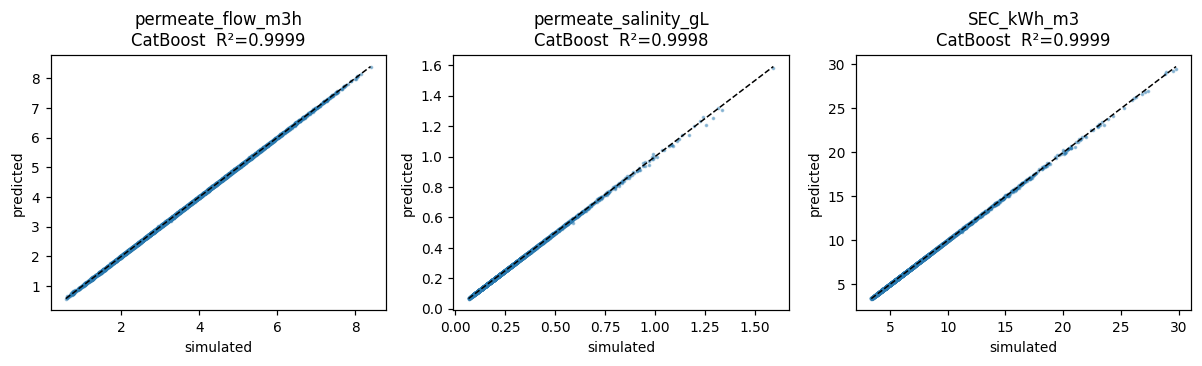

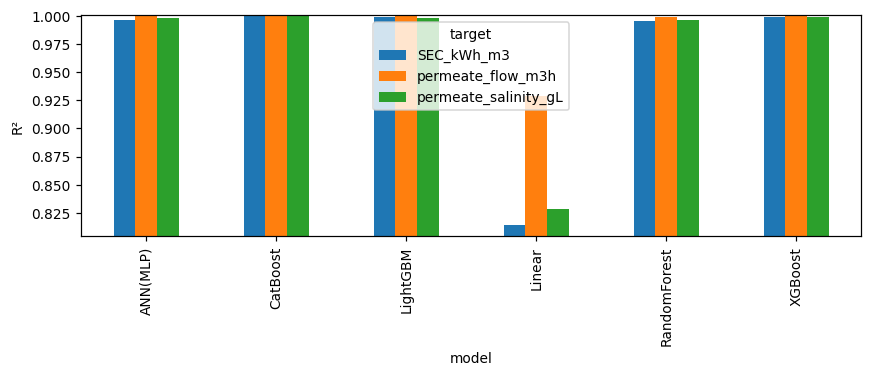

In [ ]:
print(R.drop(columns='params').round(4).to_string(index=False))
top={t:R[R.target==t].sort_values('R2',ascending=False).iloc[0].model for t in targets}; print(top)
fig,ax=plt.subplots(1,3,figsize=(11,3.4))
for a,(t,logt) in zip(ax,targets.items()):
    m=best[(t,top[t])]; p=m.predict(Xte); p=np.exp(p) if logt else p; y=df.loc[idx_te,t]
    a.scatter(y,p,s=2,alpha=.4,color='#2a7ab0'); lim=[y.min(),y.max()]; a.plot(lim,lim,'k--',lw=1)
    a.set_title(f'{t}\n{top[t]}  R²={r2_score(y,p):.4f}'); a.set_xlabel('simulated'); a.set_ylabel('predicted')
plt.tight_layout(); plt.savefig('../figures/pred_vs_actual.png'); plt.show()
piv=R.pivot(index='model',columns='target',values='R2'); piv.plot.bar(figsize=(8,3.5)); plt.ylim(piv.values.min()-0.01,1.0005); plt.ylabel('R²'); plt.tight_layout(); plt.savefig('../figures/model_comparison.png'); plt.show()

## 8. Feature importance (Explainable ML — SHAP)

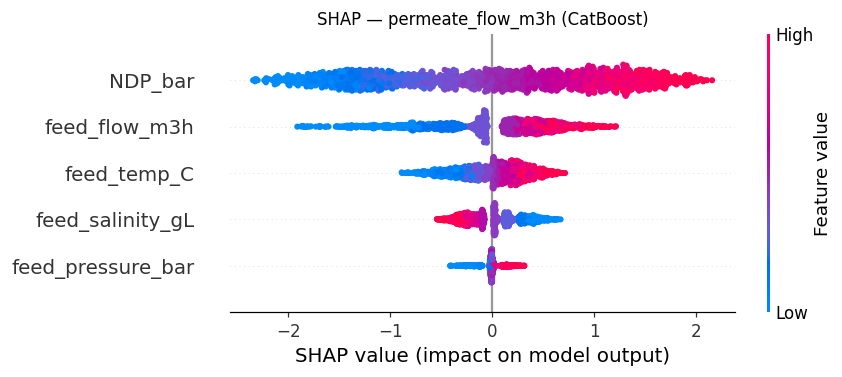

permeate_flow_m3h {'NDP_bar': 0.979, 'feed_flow_m3h': 0.5011, 'feed_temp_C': 0.2644, 'feed_salinity_gL': 0.2344, 'feed_pressure_bar': 0.065}


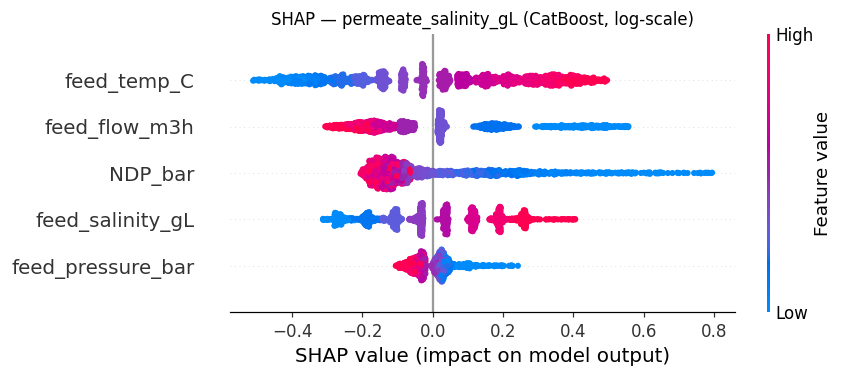

permeate_salinity_gL {'feed_temp_C': 0.2361, 'feed_flow_m3h': 0.1801, 'NDP_bar': 0.1623, 'feed_salinity_gL': 0.1504, 'feed_pressure_bar': 0.0438}


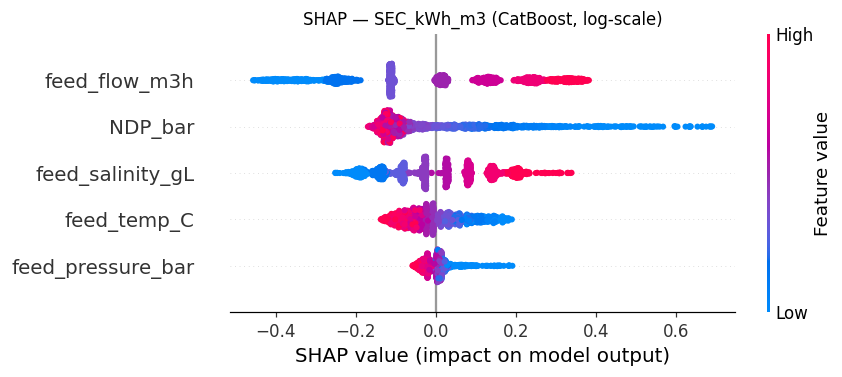

SEC_kWh_m3 {'feed_flow_m3h': 0.2045, 'NDP_bar': 0.1351, 'feed_salinity_gL': 0.1151, 'feed_temp_C': 0.0646, 'feed_pressure_bar': 0.0233}


In [ ]:
sub=Xte.sample(1500,random_state=0)
for t,logt in targets.items():
    m=best[(t,top[t])]
    ex=shap.Explainer(m.predict,sub) if top[t] in ('ANN(MLP)','Linear') else shap.TreeExplainer(m)
    sv=ex(sub); plt.figure(); shap.summary_plot(sv.values if hasattr(sv,'values') else sv,sub,show=False)
    plt.title(f'SHAP — {t} ({top[t]}{", log-scale" if logt else ""})'); plt.tight_layout(); plt.savefig(f'../figures/shap_{t}.png'); plt.show()
    v=sv.values if hasattr(sv,'values') else sv
    print(t, pd.Series(np.abs(v).mean(0),index=feats).sort_values(ascending=False).round(4).to_dict())